### **MNIST**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src.gmm import GMM
from src.knn import KNN
from src.lda import LDA
from src.pca import PCA
from src.svm import SVM
from src.plotting import plot_pca_2d


### **Load Data**

In [2]:
import os
from PIL import Image


def load_images(folder):
    images = []
    labels = []
    for digit in [2, 3, 9]:
        digit_folder = f"{folder}/{digit}"
        for filename in sorted(os.listdir(digit_folder)):
            if filename.endswith(".png"):
                with Image.open(f"{digit_folder}/{filename}") as image:
                    pixels = np.array(image.convert("L"), dtype=float)
                    images.append(pixels.ravel() / 255.0)
                    labels.append(digit)
    return np.array(images), np.array(labels)


X_train, y_train = load_images("./data/mnist/train")
X_val, y_val = load_images("./data/mnist/dev")
X_test, y_test = load_images("./data/mnist/test")


In [3]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [2 3 9]
Train: (14424, 784)
Validation: (3614, 784)
Test: (3051, 784)


### **2D PCA Visualization**

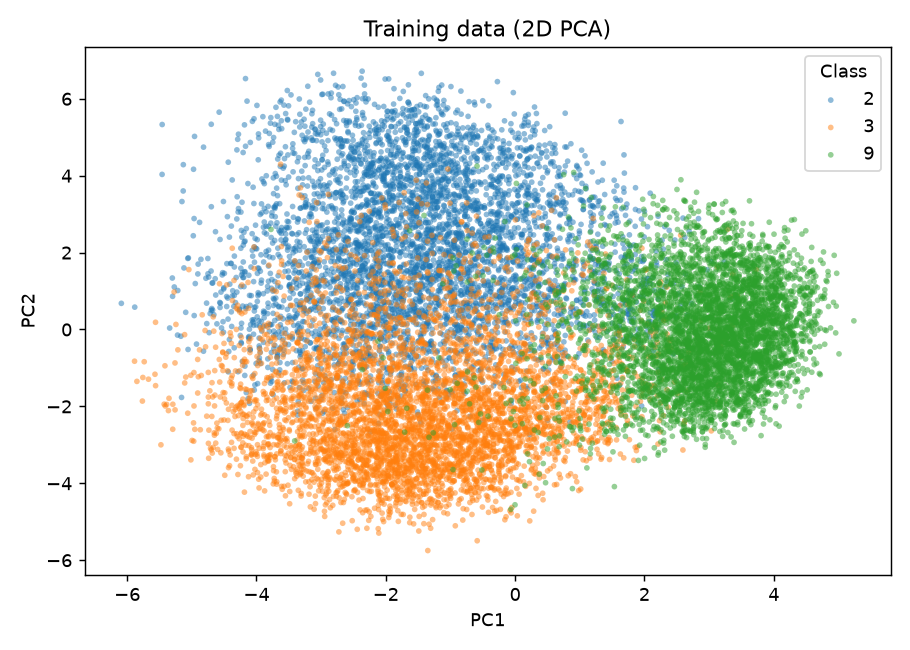

In [23]:
plot_pca_2d(X_train, y_train)


### **GMM**

In [4]:
models = []
priors = []
for label in classes:
    samples = X_train[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 2 EM iterations: 17
Class 3 EM iterations: 25
Class 9 EM iterations: 38


In [5]:
val_scores = np.column_stack([model.score_samples(X_val) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [6]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 0.966519092418373
Test accuracy: 0.97312356604392
Test confusion matrix:
 [[1006   21    5]
 [  12  989    9]
 [   5   30  974]]


### **KNN**

In [ ]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)

In [8]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.9858882125069175
Test accuracy: 0.9891838741396264
Test confusion matrix:
 [[1027    2    3]
 [   2  998   10]
 [   5   11  993]]


### **LDA**

In [9]:
lda = LDA()
lda.fit(X_train, y_train)
lda_val_predictions = lda.predict(X_val)
lda_test_predictions = lda.predict(X_test)


In [10]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.9427227448810183
Test accuracy: 0.9531301212717141
Test confusion matrix:
 [[987  24  21]
 [ 32 955  23]
 [ 12  31 966]]


### **SVM**

In [19]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 3
Gaussian sigma: 3.6147955199246256
Converged: True
Largest KKT gap: 0.0009995140989840223


In [20]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.9911455451023796
Test accuracy: 0.9934447722058342
Test confusion matrix:
 [[1029    1    2]
 [   3 1004    3]
 [   3    8  998]]


### **PCA**

In [11]:
K = 50
pca = PCA(k=K)
pca.fit(X_train)
X_train_pca = pca.transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (14424, 50)
Validation: (3614, 50)
Test: (3051, 50)


### **GMM with PCA**

In [12]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 2 EM iterations: 42
Class 3 EM iterations: 64
Class 9 EM iterations: 27


In [13]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [14]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.9811842833425567
Test accuracy: 0.98656178302196
Test confusion matrix:
 [[1022    5    5]
 [   4  998    8]
 [   5   14  990]]


### **KNN with PCA**

In [15]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [16]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.9883785279468733
Test accuracy: 0.9908226810881678
Test confusion matrix:
 [[1027    1    4]
 [   2  998   10]
 [   1   10  998]]


### **LDA with PCA**

In [17]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [18]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.9385722191477587
Test accuracy: 0.9567354965585054
Test confusion matrix:
 [[983  28  21]
 [ 31 955  24]
 [  6  22 981]]


### **SVM with PCA**

In [21]:
svm_pca = SVM()
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 3
Gaussian sigma: 3.2930964349300424
Converged: True
Largest KKT gap: 0.0009991738525534366


In [22]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.9925290536801328
Test accuracy: 0.9947558177646674
Test confusion matrix:
 [[1029    0    3]
 [   3 1004    3]
 [   0    7 1002]]


### **Accuracy Comparison**

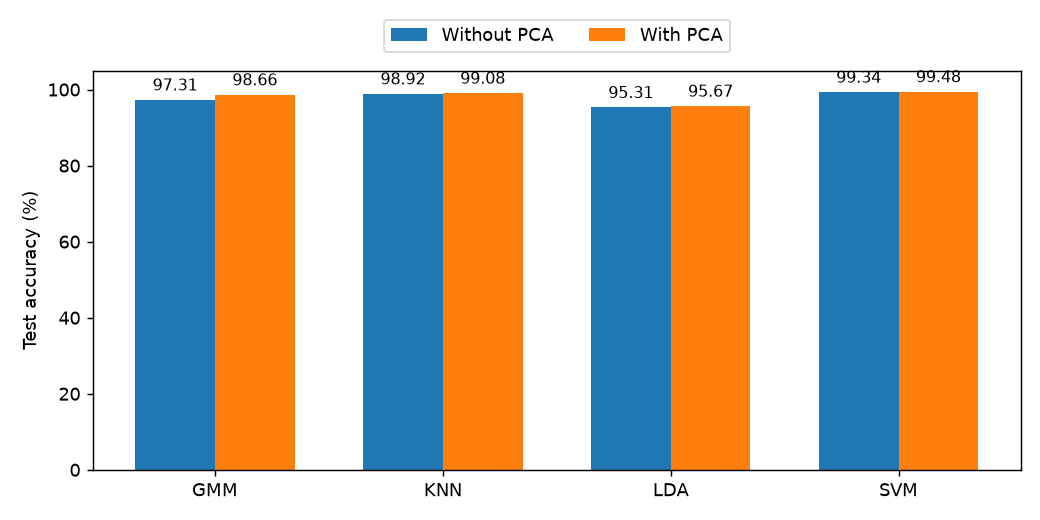

In [24]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()
